# 00.01 — Vectors & Dot Products: The Engine of Predictions

**You should already know:** Python variables, lists, functions, and elementary arithmetic.  
**By the end, you will be able to:**

1. distinguish a scalar, vector, and matrix in an ML prediction problem;
2. calculate a dot product by hand;
3. explain weights, feature contributions, and a bias term;
4. use `X @ w + b` to make a batch of predictions; and
5. diagnose common shape and elementwise-multiplication mistakes.

**Difficulty:** ★☆☆☆☆ · **Time:** 60–90 minutes

## 1. The Problem

Imagine an already-trained, fictional property-price model. For one property, it receives three facts: its size, number of bedrooms, and distance from the centre. It combines those known inputs with its known model parameters to produce one price estimate.

This scenario is illustrative, not a claim that three facts can produce a realistic real-estate model. Its purpose is to show a focused part of machine learning: how known inputs and known model parameters become one prediction.

## 2. The Toy Example or Dataset

The table below is a deliberately synthetic teaching dataset. Its units were selected for transparent arithmetic: size is counted in blocks of 10 m², bedrooms are a count, distance is measured in kilometres, and each model estimate is measured in tens of thousands of dollars (×$10k).

| Property | Size (10 m²) | Bedrooms | Distance to centre (km) | Model estimate (×$10k) |
|---|---:|---:|---:|---:|
| A | 5 | 2 | 8 | 72 |
| B | 8 | 3 | 4 | 128 |
| C | 6 | 1 | 12 | 64 |
| D | 10 | 4 | 3 | 163 |
| E | 4 | 2 | 15 | 39 |
| F | 7 | 3 | 6 | 110 |

The final **Model estimate** column is generated by the model's fixed rule; it is not a collection of observed real-world prices. For example, an estimate of 72 means 72 × $10,000 under this teaching model.

A real price model would require more data, validation, and carefully stated assumptions. This small dataset exists only to make the prediction process visible.

## 3. Intuition Before Math

Each property has three input **features**: size, bedroom count, and distance to the centre. For one property, the three ordered feature values form a **vector**. The model gives each feature a **weight**, meaning a model parameter that multiplies that feature.

That multiplication creates one contribution per feature. The contributions are added together; this paired multiplication followed by addition is the **dot product**. Finally, the model adds its **bias** (also called an intercept), a constant added after the weighted sum. The result is one **prediction**, which is a **scalar**: one numerical value.

When the six property vectors are stacked as rows, they form a **matrix**: a rectangular table of numbers. The same weighted-sum-and-bias process can then produce one estimate for each property.

```text
property features
(size, bedrooms, distance)
          |
          | multiply each feature by its matching model weight
          v
weighted feature contributions
(size contribution, bedroom contribution, distance contribution)
          |
          | add the contributions: the dot product
          v
weighted sum
          |
          | add the bias
          v
one model estimate
```

The feature values and weights are ordered to match each other. This calculation does not rely on treating an ordinary one-dimensional NumPy array as inherently a row or a column.

## 4. Mathematical Derivation

For one property, place the three input values in the feature vector $x = [x_{size}, x_{bedrooms}, x_{distance}]$. The known weight vector and bias are:

$$w = [12, 8, -3], \qquad b = 20.$$

| Quantity | Meaning | Unit |
|---|---|---|
| $x_{size}$ | Property size | 10 m² |
| $x_{bedrooms}$ | Number of bedrooms | bedrooms (a count) |
| $x_{distance}$ | Distance to the centre | km |
| $w_{size} = 12$ | Weight for size | ×$10k per 10 m² |
| $w_{bedrooms} = 8$ | Weight for bedrooms | ×$10k per bedroom |
| $w_{distance} = -3$ | Weight for distance | ×$10k per km |
| $b = 20$ | Bias (intercept) | ×$10k |
| $\hat{y}$ | Model estimate | ×$10k |

The weights have units compatible with their own features. Therefore every feature-weight product is measured in ×$10k and the contributions can be added.

The one-property prediction rule is:

$$\hat{y} = x^T w + b.$$

Here $\hat{y}$ (read “y-hat”) is the prediction. The written superscript $T$ is standard mathematical notation for pairing the feature values with the matching weight values. It does not assign an inherent row or column orientation to a NumPy array with shape `(3,)`.

The dot product is the sum of equal-position products:

$$x^T w = (x_{size} \times w_{size}) + (x_{bedrooms} \times w_{bedrooms}) + (x_{distance} \times w_{distance}).$$

For all six properties, stack the feature vectors into the matrix:

$$X = \begin{bmatrix}5 & 2 & 8 \\ 8 & 3 & 4 \\ 6 & 1 & 12 \\ 10 & 4 & 3 \\ 4 & 2 & 15 \\ 7 & 3 & 6\end{bmatrix}.$$

`X` has six rows and three feature columns. The batch rule is $\hat{y} = Xw + b$: calculate one dot product for each row, then add the same scalar bias to each weighted sum. The expected batch prediction vector is `[72, 128, 64, 163, 39, 110]`, in ×$10k units.

## 5. Manual Walkthrough

For Property A, the feature vector is $x_A = [5, 2, 8]$. Its entries mean size 5 in 10 m² units, 2 bedrooms, and distance 8 km. Use the fixed weights and bias $w = [12, 8, -3]$ and $b = 20$.

First calculate the three feature contributions:

$$\begin{aligned}
\text{size contribution} &= 5 \times 12 = 60,\\
\text{bedroom contribution} &= 2 \times 8 = 16,\\
\text{distance contribution} &= 8 \times (-3) = -24.
\end{aligned}$$

All three contributions are in ×$10k. Add them to obtain the dot product, then add the bias:

$$\begin{aligned}
x_A^T w &= (5 \times 12) + (2 \times 8) + (8 \times -3)\\
&= 60 + 16 - 24\\
&= 52,\\
\hat{y}_A &= 52 + 20 = 72.
\end{aligned}$$

So Property A's model estimate is **72 ×$10k**, or $720,000 on this synthetic scale. The positive size and bedroom contributions total 76 ×$10k; distance reduces that weighted total by 24 ×$10k; then the positive bias raises 52 ×$10k to 72 ×$10k. The negative distance contribution is a rule inside this controlled example, not a universal or causal statement about real properties.

## 6. Teaching Implementation

The model parameters are already known. The following code performs prediction only: it does not fit weights, estimate a bias, measure loss, or evaluate a model. Each row of `X` is one property; the columns are size, bedrooms, and distance in that order.

In [1]:
import numpy as np

# Rows: properties A through F.
# Columns: size (10 m²), bedrooms, distance to centre (km).
X = np.array(
    [
        [5, 2, 8],
        [8, 3, 4],
        [6, 1, 12],
        [10, 4, 3],
        [4, 2, 15],
        [7, 3, 6],
    ],
    dtype=int,
)
w = np.array([12, 8, -3], dtype=int)
b = 20
expected_predictions = np.array([72, 128, 64, 163, 39, 110], dtype=int)

def predict_one_loop(features, weights, bias):
    """Return one prediction by explicitly summing feature contributions."""
    if features.ndim != 1 or weights.ndim != 1:
        raise ValueError("features and weights must each be one-dimensional")
    if features.shape != weights.shape:
        raise ValueError("features and weights must have matching shapes")

    weighted_sum = 0
    for feature, weight in zip(features, weights):
        weighted_sum += feature * weight
    return weighted_sum + bias

def predict_batch_loop(feature_matrix, weights, bias):
    """Return one loop-based prediction for each row."""
    if feature_matrix.ndim != 2:
        raise ValueError("feature_matrix must be two-dimensional")
    if feature_matrix.shape[1] != weights.shape[0]:
        raise ValueError("each feature column needs one matching weight")
    return np.array(
        [predict_one_loop(features, weights, bias) for features in feature_matrix],
        dtype=int,
    )

x_A = X[0]
contributions_A = x_A * w
dot_product_A = x_A @ w
prediction_A = dot_product_A + b
predictions_loop = predict_batch_loop(X, w, b)
predictions_vectorized = X @ w + b

print("Property A contributions:", contributions_A)
print("Property A dot product:", dot_product_A)
print("Property A prediction:", prediction_A)
print("Batch predictions:", predictions_vectorized)

Property A contributions: [ 60  16 -24]
Property A dot product: 52
Property A prediction: 72
Batch predictions: [ 72 128  64 163  39 110]


`x_A * w` returns the three contributions `[60, 16, -24]`; it is not the final dot product. `x_A @ w` combines those matched products into the scalar weighted sum `52`. Adding `b` gives `72`.

The vectorized expression `X @ w + b` calculates one weighted sum per row and then adds the same bias to each result. The shape `(3,)` for `w` means a one-dimensional array with three components; it does not make `w` inherently a row or column vector.

## 7. Verification of Fixed Teaching Calculations

These deterministic assertions verify the required shapes, the Property A arithmetic trace, and the complete frozen batch result. `PASS` appears only after every check succeeds.

In [2]:
assert X.shape == (6, 3)
assert w.shape == (3,)
assert (X @ w + b).shape == (6,)

np.testing.assert_array_equal(contributions_A, np.array([60, 16, -24]))
assert dot_product_A == 52
assert predict_one_loop(x_A, w, b) == 72
assert prediction_A == 72

np.testing.assert_array_equal(predictions_loop, expected_predictions)
np.testing.assert_array_equal(predictions_vectorized, expected_predictions)
np.testing.assert_array_equal(predictions_loop, predictions_vectorized)

print("PASS")

PASS


## 8. Independent Cross-Check

A scalar loop and NumPy's vectorized matrix-vector expression are two presentations of the same fixed rule. The scalar loop makes each feature-weight multiplication visible; `X @ w + b` applies the same rule to all six rows. Agreement checks the implementation, not the real-world accuracy of this synthetic model.

In [3]:
def predict_batch_scalar(feature_matrix, weights, bias):
    """Predict one value per row without using matrix multiplication."""
    if feature_matrix.ndim != 2 or weights.ndim != 1:
        raise ValueError("expected a 2-D feature matrix and 1-D weights")
    if feature_matrix.shape[1] != weights.shape[0]:
        raise ValueError("each feature column needs one matching weight")

    predictions = []
    for property_features in feature_matrix:
        weighted_sum = sum(
            feature * weight for feature, weight in zip(property_features, weights)
        )
        predictions.append(weighted_sum + bias)
    return np.array(predictions, dtype=int)

predictions_scalar = predict_batch_scalar(X, w, b)
np.testing.assert_array_equal(predictions_scalar, expected_predictions)
np.testing.assert_array_equal(predictions_scalar, predictions_vectorized)
print("CROSS-CHECK PASS")

CROSS-CHECK PASS


## 9. Visual Explanation or Diagnostics

This original static chart shows the four terms that create Property A's estimate on a common ×$10k scale. The zero line and direct signed labels make the negative distance contribution visible. Colour is supplemented by labels and hatching.

**Caption:** Property A's size, bedroom, and distance contributions are `+60`, `+16`, and `-24` ×$10k. Adding the fixed bias of `+20` ×$10k gives the model estimate `72 ×$10k`.

**Text alternative:** Bar chart for synthetic Property A. The size contribution is plus 60 times ten thousand dollars, the bedroom contribution is plus 16 times ten thousand dollars, the distance contribution is minus 24 times ten thousand dollars, and the bias is plus 20 times ten thousand dollars. These terms sum to a model estimate of 72 times ten thousand dollars.

![Bar chart for synthetic Property A showing contributions of +60 for size, +16 for bedrooms, -24 for distance, and +20 for bias; these sum to 72 ×$10k.](assets/prediction_contributions.png)

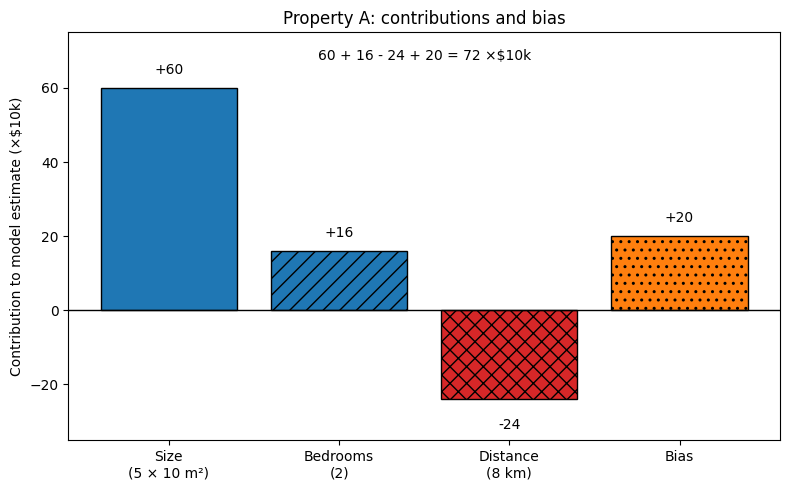

In [4]:
import matplotlib.pyplot as plt

labels = ["Size\n(5 × 10 m²)", "Bedrooms\n(2)", "Distance\n(8 km)", "Bias"]
contribution_values = np.array([60, 16, -24, 20])
bar_colors = ["tab:blue", "tab:blue", "tab:red", "tab:orange"]
bar_hatches = ["", "//", "xx", ".."]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    labels, contribution_values, color=bar_colors, edgecolor="black", linewidth=1
)

for bar, hatch, value in zip(bars, bar_hatches, contribution_values):
    bar.set_hatch(hatch)
    label_y = value + 3 if value >= 0 else value - 5
    vertical_alignment = "bottom" if value >= 0 else "top"
    ax.text(
        bar.get_x() + bar.get_width() / 2, label_y, f"{value:+d}",
        ha="center", va=vertical_alignment
    )

ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Contribution to model estimate (×$10k)")
ax.set_title("Property A: contributions and bias")
ax.text(
    0.5, 0.96, "60 + 16 - 24 + 20 = 72 ×$10k",
    transform=ax.transAxes, ha="center", va="top"
)
ax.set_ylim(-35, 75)
fig.tight_layout()
plt.show()

## 10. Failure Modes & Pitfalls

### `*` is not `@`
`x_A * w` returns `[60, 16, -24]`, a vector of contributions. `x_A @ w` returns `52`, the scalar dot product. The final prediction is `x_A @ w + b`, not `x_A * w + b`.

### Do not omit the bias
For Property A, `x_A @ w` is 52 ×$10k. The fixed model rule includes the bias, so the prediction is `52 + 20 = 72` ×$10k.

### Shape mismatch
`X` has shape `(6, 3)`, so the weight array must have three entries. A shape such as `(2,)` cannot supply one weight per feature, and NumPy rejects the matrix-vector product. Do not fix the error by silently dropping a feature.

### Matching shapes can still mean the wrong calculation
The feature order must match the weight order. Putting distance where the size value belongs can produce a number without raising an error, but it represents the wrong pairing. The input units must also match the units expected by the weights: distance is in km here, not metres.

### A `(3,)` array has no inherent orientation
A shape `(3,)` means one-dimensional with three components. If code needs a one-property feature matrix, use `x_A[None, :]` to create a shape `(1, 3)` array explicitly.

### Spot the bug
A learner writes `predictions = X * w + b` and expects one estimate per property. What is wrong?

<details><summary>Answer</summary>

`X * w` leaves a `(6, 3)` matrix of per-feature contributions. Adding `b` still leaves three values per property. Use `X @ w + b` to form one dot product per row and then add the bias.

</details>

## 11. Graded Exercises

### Conceptual 1 — Identify the objects
Classify `72`, `x_A = [5, 2, 8]`, `w = [12, 8, -3]`, `X`, and `X @ w + b` as scalars, vectors, or matrices. State what each represents.

<details><summary>Answer</summary>

`72` is a scalar prediction for Property A. `x_A` is a feature vector; `w` is a weight vector; `X` is a feature matrix; and `X @ w + b` is a vector containing six scalar predictions.

</details>

### Conceptual 2 — Calculate Property B
Use the fixed parameters to calculate the estimate for Property B, whose feature vector is `[8, 3, 4]`.

<details><summary>Answer</summary>

The contributions are `8 × 12 = 96`, `3 × 8 = 24`, and `4 × -3 = -12`. The dot product is `108`; adding the bias gives `128` ×$10k.

</details>

### Conceptual 3 — Explain the two products
Explain why `x_A * w` and `x_A @ w` return different kinds of results. What must be done after the dot product to obtain the final prediction?

<details><summary>Answer</summary>

`x_A * w` returns three elementwise contributions. `x_A @ w` sums matching products into one scalar dot product. Add the bias after that sum to obtain the prediction.

</details>

### Implementation 1 — Repair a shape error
Write a check that rejects a feature matrix with shape `(6, 3)` when its weights have shape `(4,)`. Explain what must be true before a matrix-vector prediction can be computed.

### Implementation 2 — Write a batch loop
Write a function that accepts a two-dimensional feature matrix, a one-dimensional weight array, and a scalar bias. Without using `@`, return one prediction per row. Verify its output against the frozen prediction vector and against `X @ w + b`.

### Extension — Change one synthetic input
Keep the fixed weights and bias, but change Property A to `[5, 3, 8]`. Calculate the new estimate and its change from Property A's original estimate. Explain why this is a result of the synthetic rule rather than a causal claim about real properties.

<details><summary>Answer</summary>

The contributions are `60`, `24`, and `-24`, giving a weighted sum of `60` and an estimate of `80` ×$10k. The change is `+8` ×$10k. It follows from the fixed synthetic weight; it does not establish a real-world causal effect.

</details>

## 12. References and Further Reading

- NumPy Developers. [``numpy.matmul`` — NumPy v1.26 Manual](https://numpy.org/doc/1.26/reference/generated/numpy.matmul.html). Matrix-product semantics for `@`, including the matrix-vector case.
- NumPy Developers. [``numpy.dot`` — NumPy v1.26 Manual](https://numpy.org/doc/1.26/reference/generated/numpy.dot.html). Inner products for one-dimensional arrays and dot-product behaviour.
- Zhang, Aston, Zachary C. Lipton, Mu Li, and Alexander J. Smola. [“Linear Algebra,” *Dive into Deep Learning*, §2.3](https://d2l.ai/chapter_preliminaries/linear-algebra.html). Beginner-oriented background on scalars, vectors, matrices, shapes, elementwise products, dot products, and matrix-vector products.